Cell 1: Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

def fmt_juta(x, pos=None):
    return f"{x/1_000_000:.0f} jt"

Cell 2: Load dataset

In [20]:
from google.colab import files
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
df = pd.read_excel(nama_file)
df.head()

Saving dataset_tugas_visualisasi.xlsx to dataset_tugas_visualisasi (1).xlsx


,ID,Nama,Usia,Jenis_Kelamin,Kota,Pendapatan,Pekerjaan,Rating_Kepuasan,Tanggal_Transaksi,Status_Member
0,1,Ahmad Fauzi,58,L,Jakarta,7614226,Karyawan Swasta,4,2026-01-15,Gold
1,2,Siti Aminah,33,P,Surabaya,4719583,Pns,5,2026-01-16,Silver
2,3,Budi Santoso,52,L,Yogyakarta,10078673,Wiraswasta,3,2026-01-17,Bronze
3,4,Dewi Lestari,35,L,Jakarta,4571945,Karyawan,4,2026-01-18,Gold
4,5,Rian Hidayat,31,P,Yogyakarta,13100198,Pns,5,2026-01-19,Silver


Cell 3: Eksplorasi awal

In [21]:
print("Jumlah baris & kolom:", df.shape)
df.info()

Jumlah baris & kolom: (100, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   ID                 100 non-null    int64 
 1   Nama               100 non-null    object
 2   Usia               100 non-null    int64 
 3   Jenis_Kelamin      100 non-null    object
 4   Kota               100 non-null    object
 5   Pendapatan         100 non-null    int64 
 6   Pekerjaan          100 non-null    object
 7   Rating_Kepuasan    100 non-null    int64 
 8   Tanggal_Transaksi  100 non-null    object
 9   Status_Member      100 non-null    object
dtypes: int64(4), object(6)
memory usage: 7.9+ KB


Cell 4: Statistik deskriptif

In [22]:
df.describe().round(2)

,ID,Usia,Pendapatan,Rating_Kepuasan
count,100.00,100.00,100.00,100.00
mean,51.38,39.29,8649068.02,3.18
std,29.20,11.33,3146740.76,1.35
min,1.00,20.00,3598919.00,1.00
25%,26.75,31.00,6085793.25,2.00
50%,51.50,36.00,8059089.50,3.00
75%,76.25,50.00,10734860.25,4.00
max,101.00,59.00,14787638.00,5.00


Cell 5: Cek missing value dan duplikat

In [23]:
print("Missing value per kolom:")
print(df.isna().sum())
print()
print("Baris duplikat persis      :", df.duplicated().sum())
print("Duplikat (selain kolom ID) :", df.drop(columns="ID").duplicated().sum())

Missing value per kolom:
ID                   0
Nama                 0
Usia                 0
Jenis_Kelamin        0
Kota                 0
Pendapatan           0
Pekerjaan            0
Rating_Kepuasan      0
Tanggal_Transaksi    0
Status_Member        0
dtype: int64

Baris duplikat persis      : 0
Duplikat (selain kolom ID) : 1


Cell 6: Lihat baris duplikat

In [24]:
df[df.drop(columns="ID").duplicated(keep=False)]

,ID,Nama,Usia,Jenis_Kelamin,Kota,Pendapatan,Pekerjaan,Rating_Kepuasan,Tanggal_Transaksi,Status_Member
10,11,Agus Setiawan,31,L,Bandung,4714803,Buruh,3,2026-01-25,Silver
11,12,Agus Setiawan,31,L,Bandung,4714803,Buruh,3,2026-01-25,Silver


Cell 7: Pembersihan dan persiapan data

In [25]:
df["Tanggal_Transaksi"] = pd.to_datetime(df["Tanggal_Transaksi"])

df["Pekerjaan"] = (
    df["Pekerjaan"].str.strip()
    .replace({"Karyawan": "Karyawan Swasta", "Pns": "PNS"})
)

df["Gender"] = df["Jenis_Kelamin"].map({"L": "Laki-laki", "P": "Perempuan"})

df["Kelompok_Usia"] = pd.cut(
    df["Usia"],
    bins=[19, 29, 39, 49, 59],
    labels=["20-29", "30-39", "40-49", "50-59"],
)

df["Bulan"] = df["Tanggal_Transaksi"].dt.to_period("M").dt.to_timestamp()

urut_member = ["Bronze", "Silver", "Gold"]
warna_member = {"Bronze": "#cd7f32", "Silver": "#9e9e9e", "Gold": "#f2b705"}
df["Status_Member"] = pd.Categorical(df["Status_Member"], categories=urut_member, ordered=True)

print(df["Pekerjaan"].value_counts())
df.head()

Pekerjaan
Karyawan Swasta     20
Mahasiswa           17
PNS                 14
Wiraswasta          14
Artis               10
Guru                10
Ibu Rumah Tangga     8
Buruh                7
Name: count, dtype: int64


,ID,Nama,Usia,Jenis_Kelamin,Kota,Pendapatan,Pekerjaan,Rating_Kepuasan,Tanggal_Transaksi,Status_Member,Gender,Kelompok_Usia,Bulan
0,1,Ahmad Fauzi,58,L,Jakarta,7614226,Karyawan Swasta,4,2026-01-15,Gold,Laki-laki,50-59,2026-01-01
1,2,Siti Aminah,33,P,Surabaya,4719583,PNS,5,2026-01-16,Silver,Perempuan,30-39,2026-01-01
2,3,Budi Santoso,52,L,Yogyakarta,10078673,Wiraswasta,3,2026-01-17,Bronze,Laki-laki,50-59,2026-01-01
3,4,Dewi Lestari,35,L,Jakarta,4571945,Karyawan Swasta,4,2026-01-18,Gold,Laki-laki,30-39,2026-01-01
4,5,Rian Hidayat,31,P,Yogyakarta,13100198,PNS,5,2026-01-19,Silver,Perempuan,30-39,2026-01-01


Cell 8: Jumlah pelanggan per kota

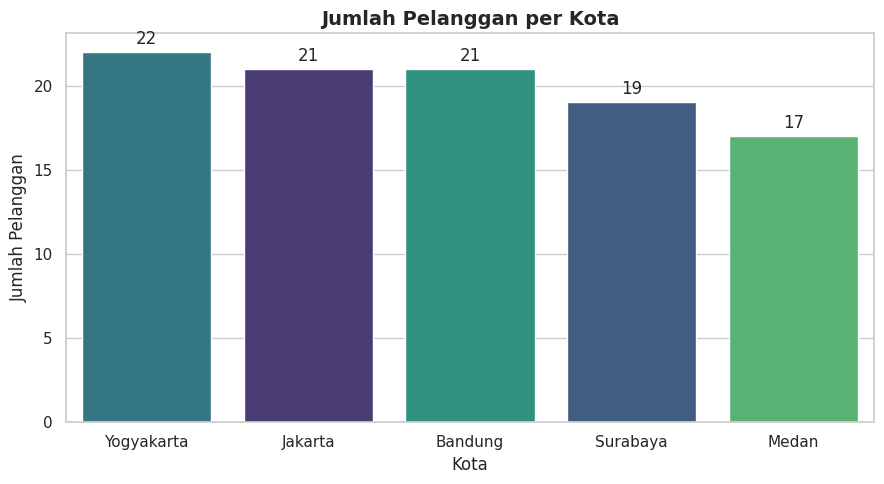

In [26]:
urut_kota = df["Kota"].value_counts().index

fig, ax = plt.subplots()
sns.countplot(data=df, x="Kota", order=urut_kota, hue="Kota", legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=3)
ax.set_title("Jumlah Pelanggan per Kota")
ax.set_xlabel("Kota")
ax.set_ylabel("Jumlah Pelanggan")
plt.tight_layout()
plt.show()

Cell 9: Proporsi status member

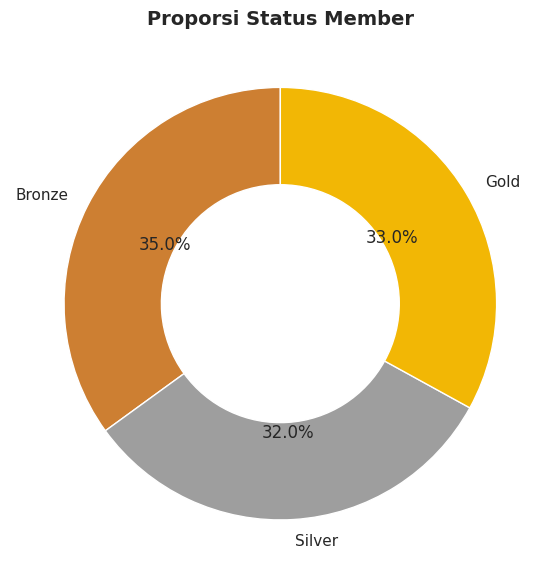

In [27]:
cnt = df["Status_Member"].value_counts().reindex(urut_member)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    cnt, labels=cnt.index, autopct="%1.1f%%", startangle=90,
    colors=[warna_member[m] for m in cnt.index],
    wedgeprops=dict(width=0.45, edgecolor="white"),
)
ax.set_title("Proporsi Status Member")
plt.tight_layout()
plt.show()

Cell 10: Distribusi usia

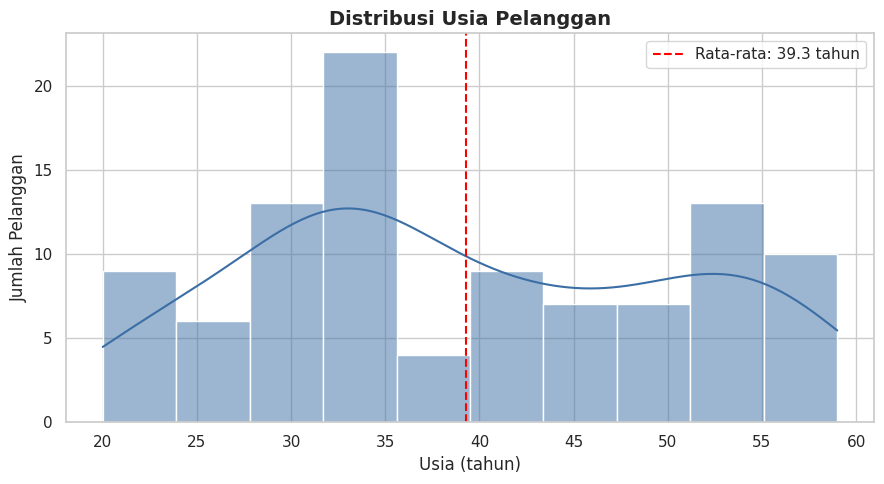

In [28]:
fig, ax = plt.subplots()
sns.histplot(df["Usia"], bins=10, kde=True, color="#3b6ea5", ax=ax)
ax.axvline(df["Usia"].mean(), color="red", linestyle="--",
           label=f"Rata-rata: {df['Usia'].mean():.1f} tahun")
ax.set_title("Distribusi Usia Pelanggan")
ax.set_xlabel("Usia (tahun)")
ax.set_ylabel("Jumlah Pelanggan")
ax.legend()
plt.tight_layout()
plt.show()

Cell 11: Rata-rata pendapatan per pekerjaan

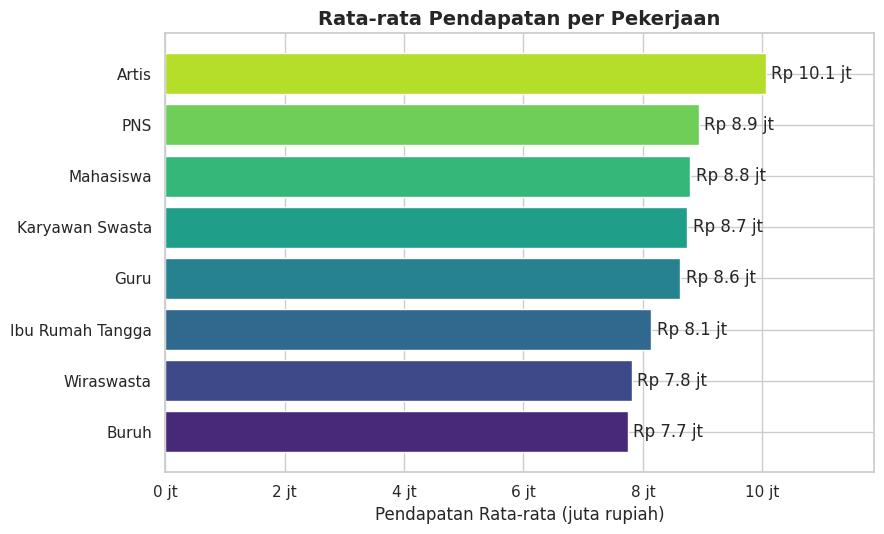

In [29]:
rata = df.groupby("Pekerjaan")["Pendapatan"].mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(rata.index, rata.values, color=sns.color_palette("viridis", len(rata)))
ax.bar_label(bars, labels=[f"Rp {v/1e6:.1f} jt" for v in rata.values], padding=4)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(fmt_juta))
ax.set_xlim(0, rata.max() * 1.18)
ax.set_title("Rata-rata Pendapatan per Pekerjaan")
ax.set_xlabel("Pendapatan Rata-rata (juta rupiah)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Cell 12: Sebaran pendapatan per status member

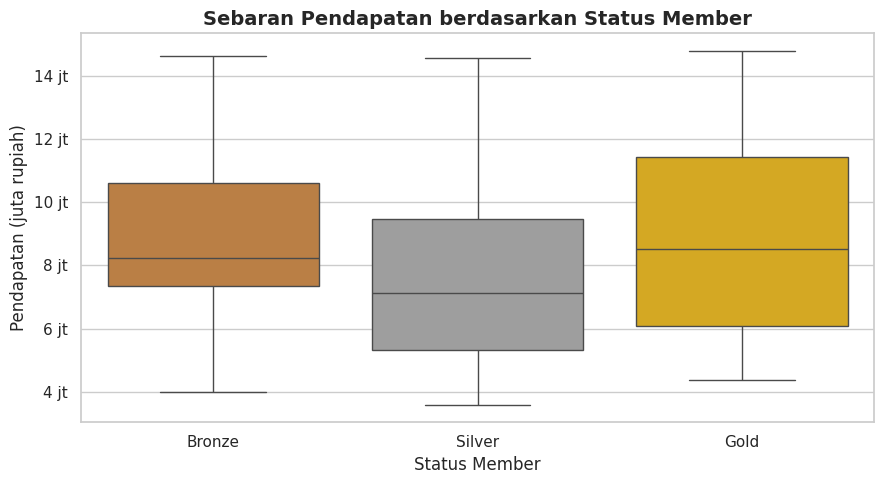

In [30]:
fig, ax = plt.subplots()
sns.boxplot(
    data=df, x="Status_Member", y="Pendapatan", order=urut_member,
    hue="Status_Member", palette=warna_member, legend=False, ax=ax,
)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_juta))
ax.set_title("Sebaran Pendapatan berdasarkan Status Member")
ax.set_xlabel("Status Member")
ax.set_ylabel("Pendapatan (juta rupiah)")
plt.tight_layout()
plt.show()

Cell 13: Distribusi rating kepuasan

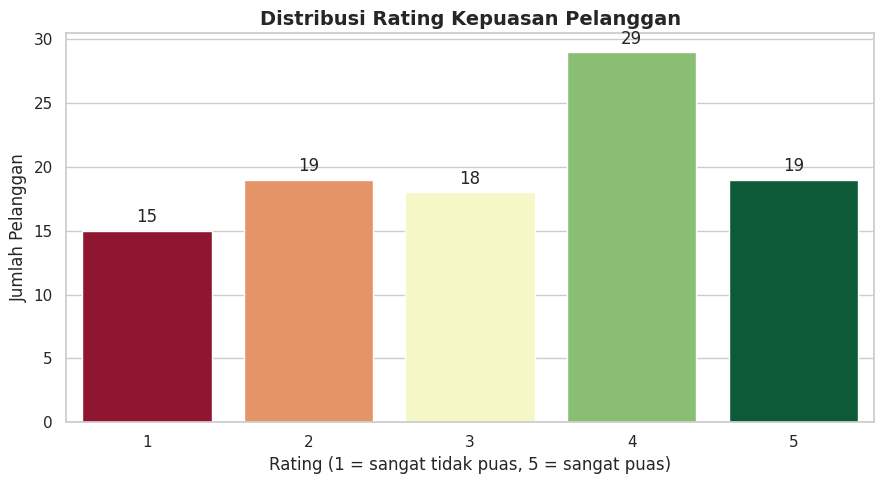

In [31]:
fig, ax = plt.subplots()
sns.countplot(data=df, x="Rating_Kepuasan", order=[1, 2, 3, 4, 5],
              hue="Rating_Kepuasan", palette="RdYlGn", legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=3)
ax.set_title("Distribusi Rating Kepuasan Pelanggan")
ax.set_xlabel("Rating (1 = sangat tidak puas, 5 = sangat puas)")
ax.set_ylabel("Jumlah Pelanggan")
plt.tight_layout()
plt.show()

Cell 14: Heatmap rating per kota dan member

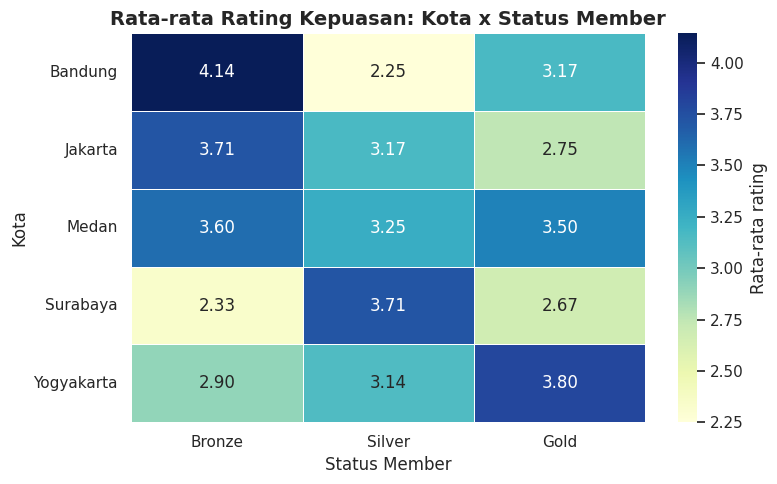

In [32]:
pivot_rating = df.pivot_table(index="Kota", columns="Status_Member",
                              values="Rating_Kepuasan", aggfunc="mean", observed=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_rating, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "Rata-rata rating"}, ax=ax)
ax.set_title("Rata-rata Rating Kepuasan: Kota x Status Member")
ax.set_xlabel("Status Member")
ax.set_ylabel("Kota")
plt.tight_layout()
plt.show()

Cell 15: Tren transaksi per bulan

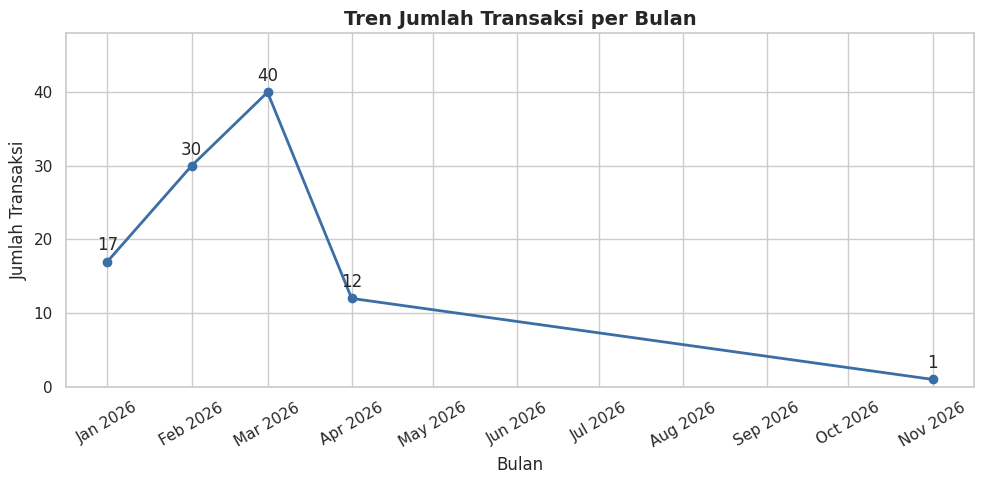

In [33]:
import matplotlib.dates as mdates

tren = df.groupby("Bulan").size()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tren.index, tren.values, marker="o", color="#3b6ea5", linewidth=2)
for x, y in zip(tren.index, tren.values):
    ax.annotate(y, (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("Tren Jumlah Transaksi per Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Transaksi")
ax.set_ylim(0, tren.max() * 1.2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Cell 16: Hubungan usia dan pendapatan

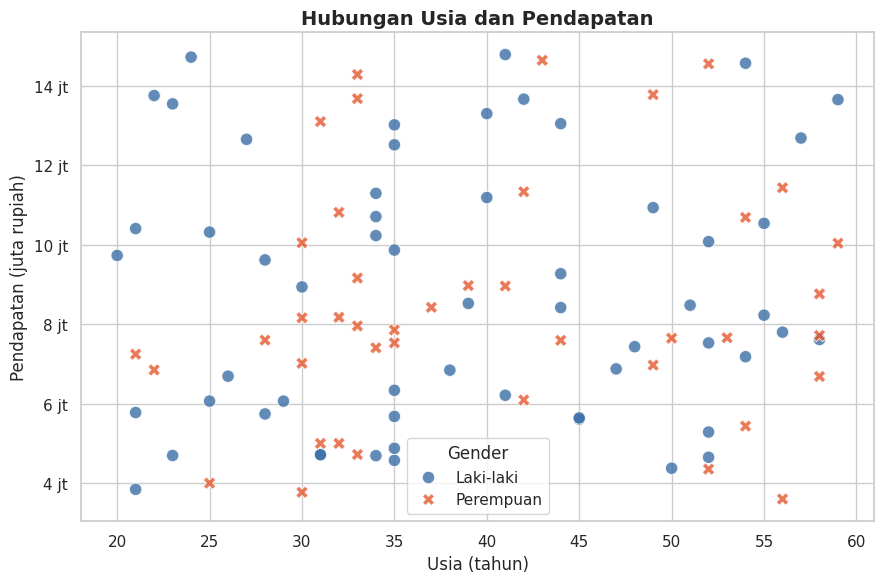

In [34]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="Usia", y="Pendapatan", hue="Gender", style="Gender",
                s=80, alpha=0.8, palette=["#3b6ea5", "#e4572e"], ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_juta))
ax.set_title("Hubungan Usia dan Pendapatan")
ax.set_xlabel("Usia (tahun)")
ax.set_ylabel("Pendapatan (juta rupiah)")
plt.tight_layout()
plt.show()

Cell 17: Matriks korelasi

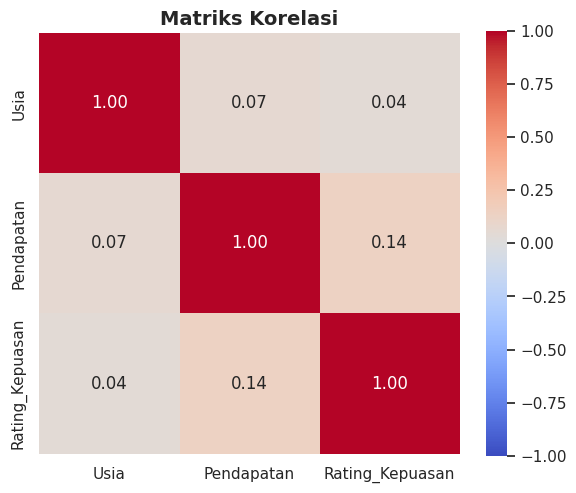

In [35]:
kolom_num = ["Usia", "Pendapatan", "Rating_Kepuasan"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df[kolom_num].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Matriks Korelasi")
plt.tight_layout()
plt.show()

Cell 18: Visualisasi interaktif (sunburst)

In [37]:
kota_top = df["Kota"].value_counts()
member_top = df["Status_Member"].value_counts()
kerja_income = df.groupby("Pekerjaan")["Pendapatan"].mean().sort_values(ascending=False)
puas = (df["Rating_Kepuasan"] >= 4).mean() * 100
korelasi = df["Usia"].corr(df["Pendapatan"])

print(f"1. Jumlah data                       : {len(df)} baris")
print(f"2. Kota dengan pelanggan terbanyak   : {kota_top.index[0]} ({kota_top.iloc[0]} pelanggan)")
print(f"3. Status member terbanyak           : {member_top.index[0]} ({member_top.iloc[0]} pelanggan)")
print(f"4. Rata-rata usia                    : {df['Usia'].mean():.1f} tahun")
print(f"5. Rata-rata pendapatan              : Rp {df['Pendapatan'].mean():,.0f}")
print(f"6. Pekerjaan berpendapatan tertinggi : {kerja_income.index[0]} (Rp {kerja_income.iloc[0]:,.0f})")
print(f"7. Pekerjaan berpendapatan terendah  : {kerja_income.index[-1]} (Rp {kerja_income.iloc[-1]:,.0f})")
print(f"8. Pelanggan puas (rating 4-5)       : {puas:.1f}%")
print(f"9. Rata-rata rating                  : {df['Rating_Kepuasan'].mean():.2f} dari 5")
print(f"10. Korelasi usia vs pendapatan      : {korelasi:.2f}")

1. Jumlah data                       : 100 baris
2. Kota dengan pelanggan terbanyak   : Yogyakarta (22 pelanggan)
3. Status member terbanyak           : Bronze (35 pelanggan)
4. Rata-rata usia                    : 39.3 tahun
5. Rata-rata pendapatan              : Rp 8,649,068
6. Pekerjaan berpendapatan tertinggi : Artis (Rp 10,057,978)
7. Pekerjaan berpendapatan terendah  : Buruh (Rp 7,741,878)
8. Pelanggan puas (rating 4-5)       : 48.0%
9. Rata-rata rating                  : 3.18 dari 5
10. Korelasi usia vs pendapatan      : 0.07


In [36]:
fig = px.sunburst(
    df, path=["Kota", "Status_Member", "Gender"],
    title="Komposisi Pelanggan: Kota > Status Member > Gender",
    color_discrete_sequence=px.colors.qualitative.Set2,
)
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10), height=600)
fig.show()

/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



Cell 19: Ringkasan insight otomatis